# Ejemplos aleatorios por tipo de borde y de base

Se selecciona **una imagen aleatoria por cada tipo de `Borde`** entre los recortes con `borde_origen == "tope"`, y **una por cada tipo de `Base`** entre los recortes con `borde_origen == "base"`.

Se usa la metadata y las imágenes de `../data/06.mitades`. Las rutas se reconstruyen buscando cada `Identificador` entre los PNG de sus carpetas de clase. Las imágenes se muestran sin aumentación ni normalización. No se necesita cargar el modelo ni ejecutar UMAP.

La selección se hace entre imágenes (cada mitad es una candidata). Los valores sin tipo se excluyen y se informa su cantidad. Dejá `SEMILLA = None` para obtener nuevas muestras al ejecutar la selección, o asigná un entero para reproducirlas.

In [3]:
import math

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from PIL import Image

from vasijas.config import load_config
from vasijas.metadata import cargar_metadata
from vasijas.paths import ProjectPaths, ruta_relativa

CONFIG = load_config()
PATHS = ProjectPaths.from_root(CONFIG.project_root)
DATA_DIR = PATHS.DATA_MITADES
SEMILLA = None  # Por ejemplo, 42 para una selección reproducible.
COLUMNAS_GALERIA = 4

print(f"Metadata: {ruta_relativa(DATA_DIR / 'metadata.csv')}")

Metadata: data\06.mitades\metadata.csv


## Carga y disponibilidad de tipos

Se verifica que cada tipo tenga recortes del origen correspondiente. Un tipo sin candidatos detiene la selección para evitar una galería incompleta.

In [4]:
metadata = cargar_metadata(DATA_DIR)
requeridas = {
    "Identificador",
    "Borde",
    "Base",
    "borde_origen",
    "porcentaje_avance",
}
faltantes = requeridas - set(metadata.columns)
if faltantes:
    raise ValueError(f"Faltan columnas en metadata: {sorted(faltantes)}")
if metadata.empty:
    raise ValueError("La metadata no contiene imágenes.")

# La metadata de mitades no incluye ruta_relativa: localizar cada PNG por su identificador.
rutas_por_identificador = {}
for ruta in sorted(DATA_DIR.rglob("*.png")):
    if ruta.stem in rutas_por_identificador:
        raise ValueError(
            f"Identificador de imagen duplicado en las carpetas: {ruta.stem}"
        )
    rutas_por_identificador[ruta.stem] = ruta.relative_to(DATA_DIR).as_posix()

metadata["ruta_relativa"] = metadata["Identificador"].map(rutas_por_identificador)
sin_imagen = metadata.loc[metadata["ruta_relativa"].isna(), "Identificador"]
if not sin_imagen.empty:
    raise FileNotFoundError(
        f"No se encontraron PNG para {len(sin_imagen)} identificadores: "
        f"{sin_imagen.head(10).tolist()}"
    )

metadata["borde_origen"] = (
    metadata["borde_origen"].astype("string").str.strip().str.lower()
)
for columna in ["Borde", "Base"]:
    metadata[columna] = (
        metadata[columna].astype("string").str.strip().replace("", pd.NA)
    )


def candidatos_por_tipo(columna, origen):
    tipos = set(metadata[columna].dropna())
    candidatos = metadata.loc[
        metadata["borde_origen"].eq(origen) & metadata[columna].notna()
    ].copy()
    sin_candidatos = tipos - set(candidatos[columna])
    if not tipos or sin_candidatos:
        raise ValueError(
            f"{columna}: tipos sin recortes de origen {origen}: {sorted(sin_candidatos)}"
        )
    if candidatos[["Identificador", "ruta_relativa"]].isna().any().any():
        raise ValueError(f"{columna}: hay candidatos sin identificador o ruta.")
    print(
        f"{columna}: {len(tipos)} tipos; {len(candidatos)} imágenes candidatas; "
        f"{int(metadata.loc[metadata['borde_origen'].eq(origen), columna].isna().sum())} "
        "imágenes excluidas por tipo faltante."
    )
    display(
        candidatos.groupby(columna).size().rename("imagenes_disponibles").to_frame()
    )
    return candidatos


candidatos_bordes = candidatos_por_tipo("Borde", "tope")
candidatos_bases = candidatos_por_tipo("Base", "base")

Borde: 15 tipos; 1081 imágenes candidatas; 0 imágenes excluidas por tipo faltante.


,imagenes_disponibles
Borde,
1,418
11,154
12,8
13,15
14,33
15,15
16,1
17,36
2,3


Base: 4 tipos; 1081 imágenes candidatas; 0 imágenes excluidas por tipo faltante.


,imagenes_disponibles
Base,
1,623
2,405
3,28
4,25


## Selección aleatoria

Reejecutá esta celda y las galerías para cambiar los ejemplos. La tabla conserva la ruta de cada imagen seleccionada.

In [5]:
rng = np.random.default_rng(SEMILLA)


def seleccionar_por_tipo(candidatos, columna):
    def ordenar_tipo(valor):
        try:
            return (0, float(valor))
        except ValueError:
            return (1, str(valor))

    seleccion = []
    for tipo in sorted(candidatos[columna].unique(), key=ordenar_tipo):
        grupo = candidatos.loc[candidatos[columna].eq(tipo)].sort_values(
            "ruta_relativa"
        )
        seleccion.append(grupo.iloc[int(rng.integers(len(grupo)))])
    resultado = pd.DataFrame(seleccion).reset_index(drop=True)
    assert resultado[columna].is_unique
    assert set(resultado[columna]) == set(candidatos[columna])
    return resultado


ejemplos_bordes = seleccionar_por_tipo(candidatos_bordes, "Borde")
ejemplos_bases = seleccionar_por_tipo(candidatos_bases, "Base")

for columna, ejemplos in [("Borde", ejemplos_bordes), ("Base", ejemplos_bases)]:
    print(f"Ejemplos de {columna.lower()}: {len(ejemplos)}")
    display(
        ejemplos[
            [
                columna,
                "Identificador",
                "borde_origen",
                "porcentaje_avance",
                "ruta_relativa",
            ]
        ]
    )

Ejemplos de borde: 15


,Borde,Identificador,borde_origen,porcentaje_avance,ruta_relativa
0,1,cc_12_1_tope,tope,50.0,clase08/cc_12_1_tope.png
1,2,gu_057_tope,tope,50.0,clase10/gu_057_tope.png
2,3,gi_09_tope,tope,50.0,clase09/gi_09_tope.png
3,4,ba_68_2_tope,tope,50.0,clase11/ba_68_2_tope.png
4,6,al_07b_tope,tope,50.0,clase10/al_07b_tope.png
5,7,ba_5_4_tope,tope,50.0,clase10/ba_5_4_tope.png
6,8,tu_110_3_tope,tope,50.0,clase01/tu_110_3_tope.png
7,9,el_01_6_tope,tope,50.0,clase10/el_01_6_tope.png
8,11,cc_10_6_tope,tope,50.0,clase10/cc_10_6_tope.png
9,12,tu_07_tope,tope,50.0,clase10/tu_07_tope.png


Ejemplos de base: 4


,Base,Identificador,borde_origen,porcentaje_avance,ruta_relativa
0,1,tu_19_12_base,base,50.0,clase08/tu_19_12_base.png
1,2,mb_28_base,base,50.0,clase10/mb_28_base.png
2,3,al_06e_base,base,50.0,clase10/al_06e_base.png
3,4,ba_45_3_base,base,50.0,clase01/ba_45_3_base.png


In [6]:
def mostrar_galeria(ejemplos, columna, titulo):
    filas = math.ceil(len(ejemplos) / COLUMNAS_GALERIA)
    figura, ejes = plt.subplots(
        filas,
        COLUMNAS_GALERIA,
        figsize=(4 * COLUMNAS_GALERIA, 4.5 * filas),
        squeeze=False,
    )
    try:
        for eje in ejes.flat:
            eje.axis("off")
        for eje, (_, ejemplo) in zip(ejes.flat, ejemplos.iterrows()):
            ruta = DATA_DIR / ejemplo["ruta_relativa"]
            if not ruta.is_file():
                raise FileNotFoundError(f"No existe la imagen seleccionada: {ruta}")
            with Image.open(ruta) as imagen:
                eje.imshow(imagen.convert("RGB"))
            eje.set_title(
                f"{columna} {ejemplo[columna]}"
                + chr(10)
                + str(ejemplo["Identificador"])
                + chr(10)
                + f"Origen: {ejemplo['borde_origen']} · "
                + f"{ejemplo['porcentaje_avance']:g} %",
                fontsize=10,
            )
        figura.suptitle(titulo, fontsize=16)
        figura.tight_layout(rect=(0, 0, 1, 0.96))
        display(figura)
    finally:
        plt.close(figura)

## Una imagen por tipo de borde

Recortes que conservan el tope del perfil.

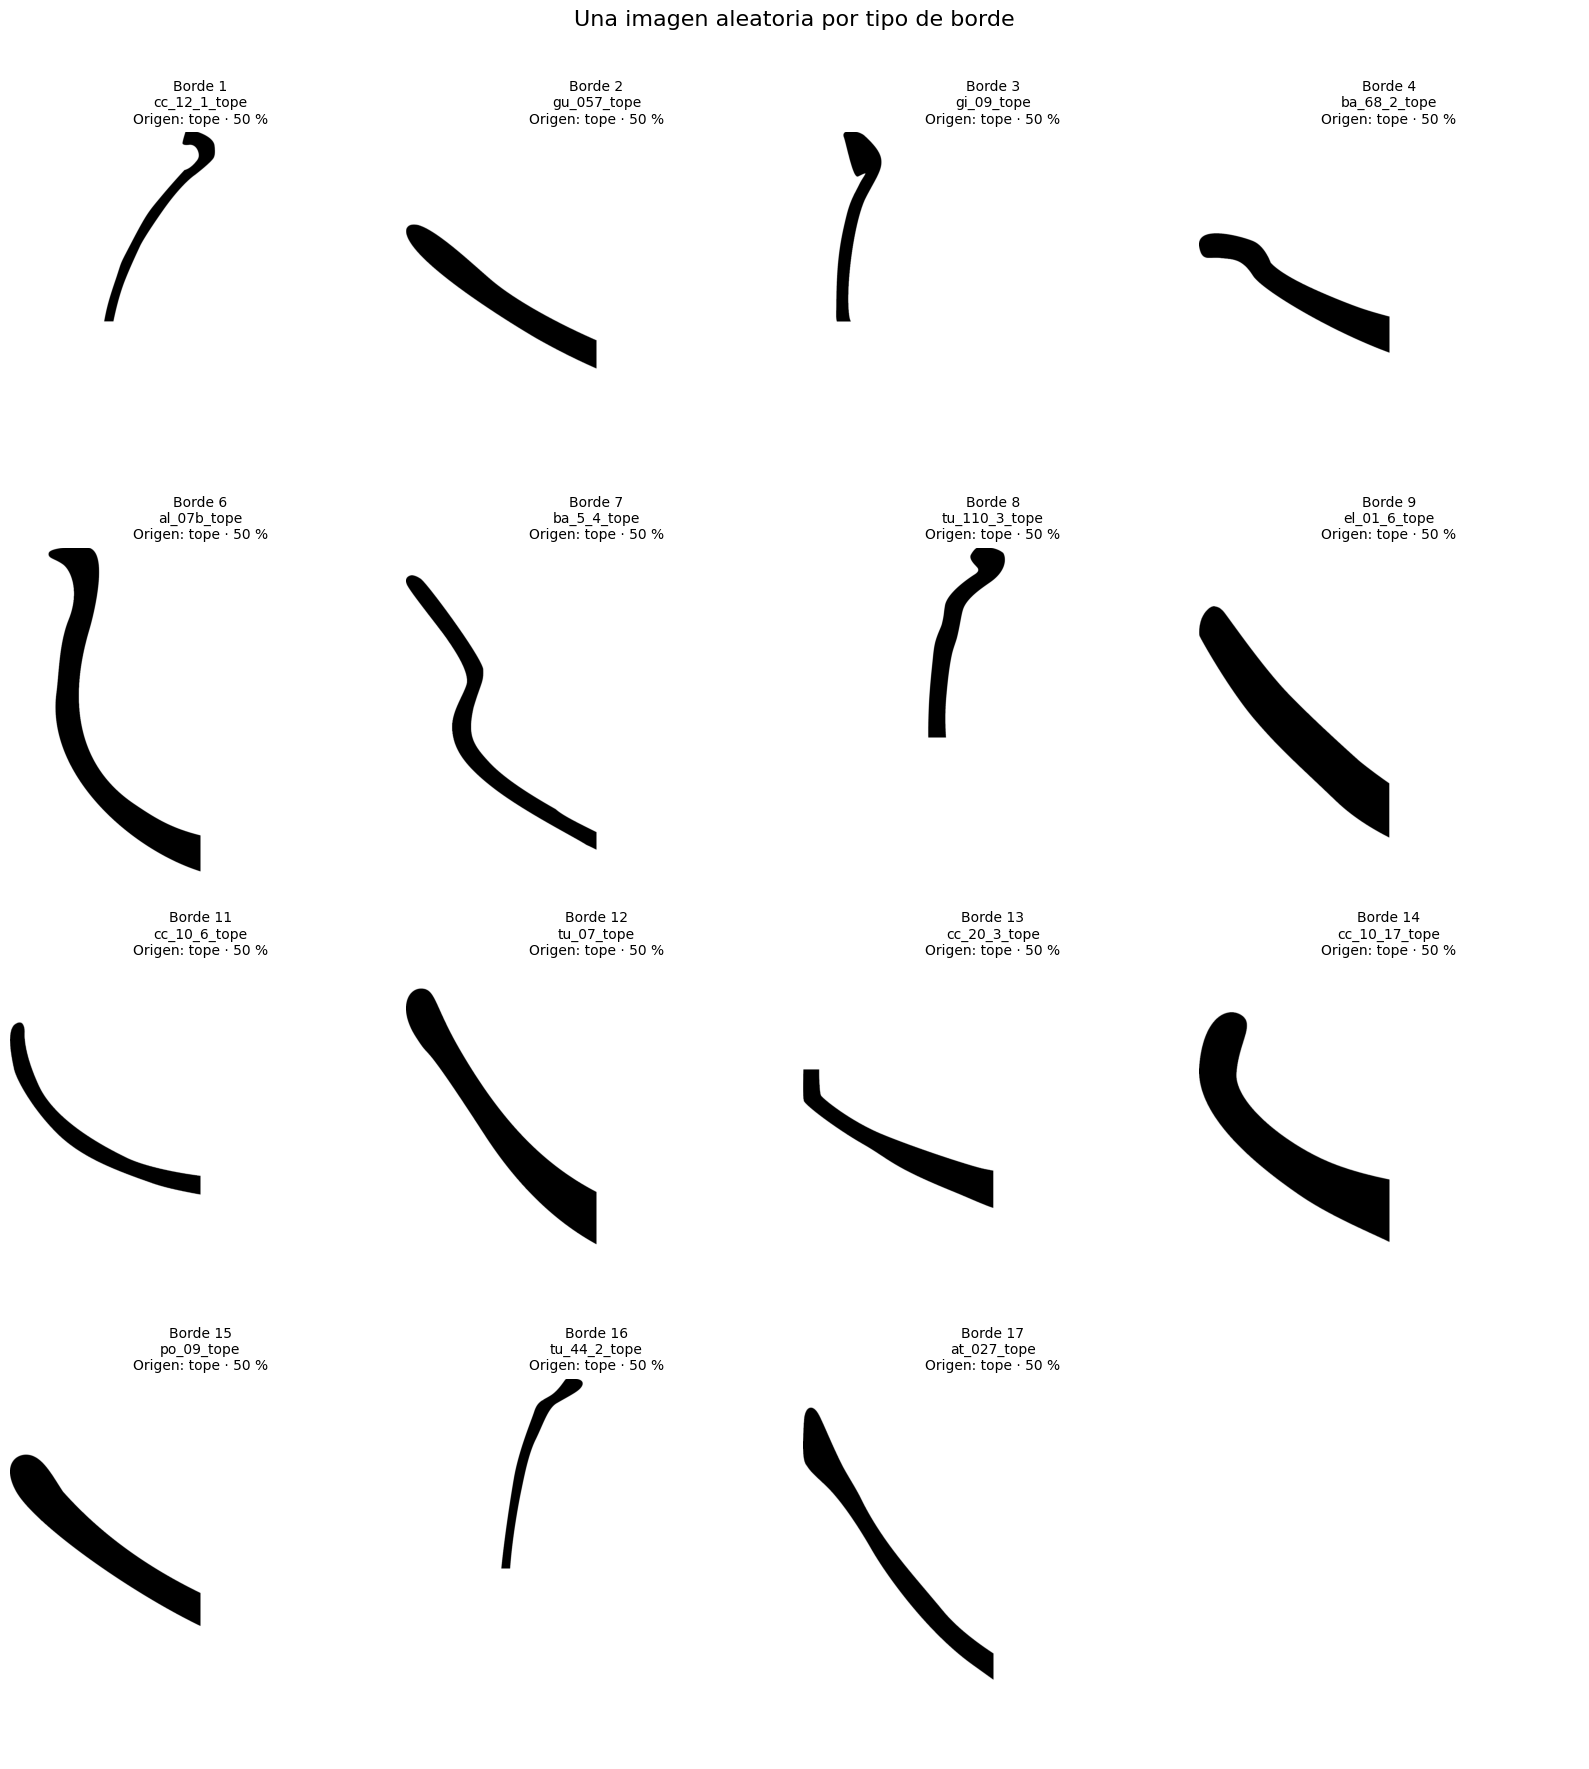

In [7]:
mostrar_galeria(ejemplos_bordes, "Borde", "Una imagen aleatoria por tipo de borde")

## Una imagen por tipo de base

Recortes que conservan la base del perfil.

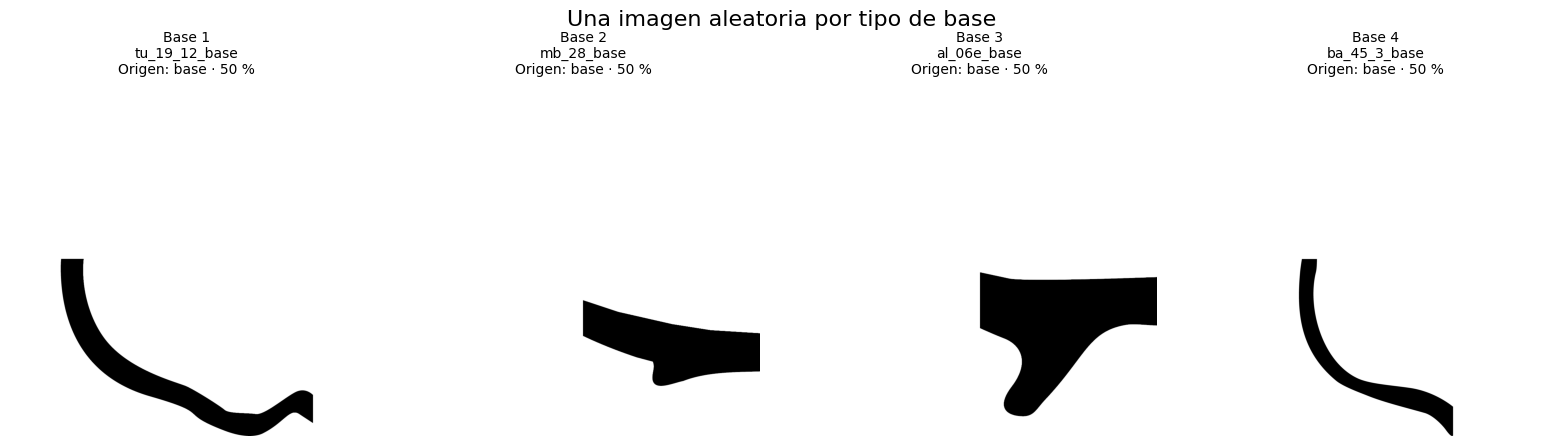

In [8]:
mostrar_galeria(ejemplos_bases, "Base", "Una imagen aleatoria por tipo de base")